In [1]:
import matplotlib.pyplot as plt
from matplotlib import cm, colors
import mpl_toolkits.mplot3d.art3d as art3d

import numpy as np
import h5py

import pickle

from glob import glob
import os
from decimal import Decimal

import matplotlib.colors as colors

plt.rcParams.update({'font.size': 15})

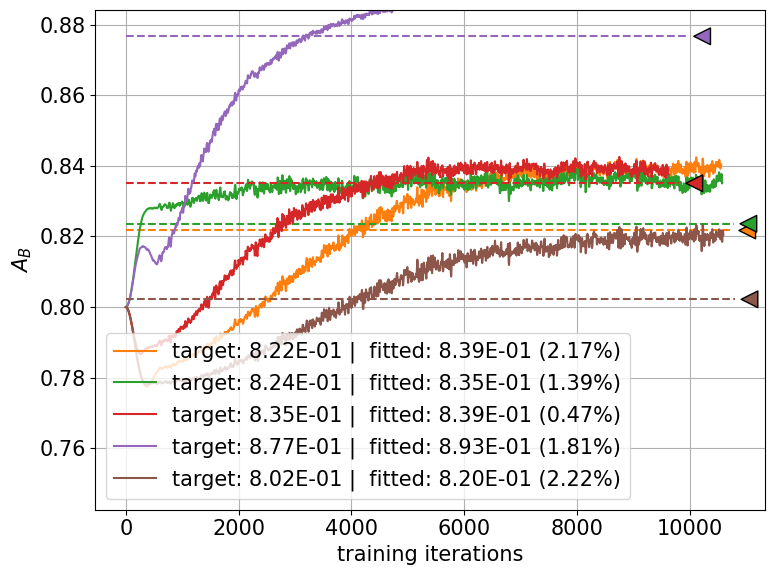

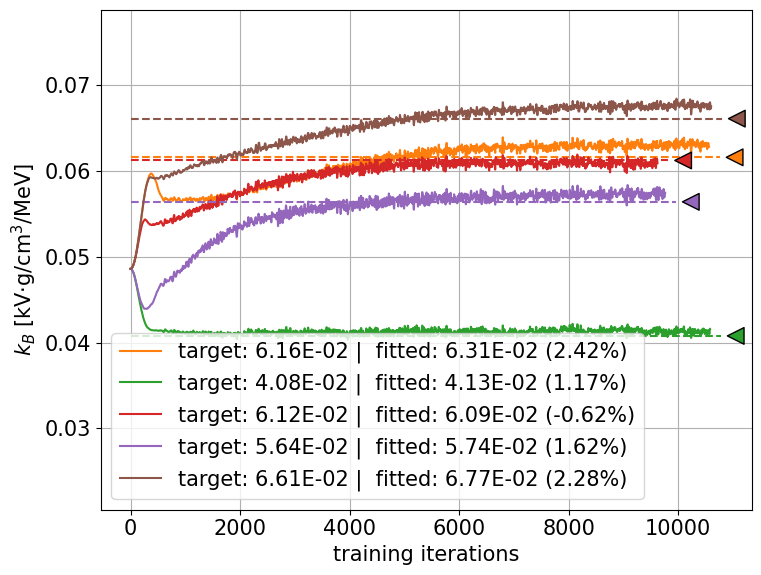

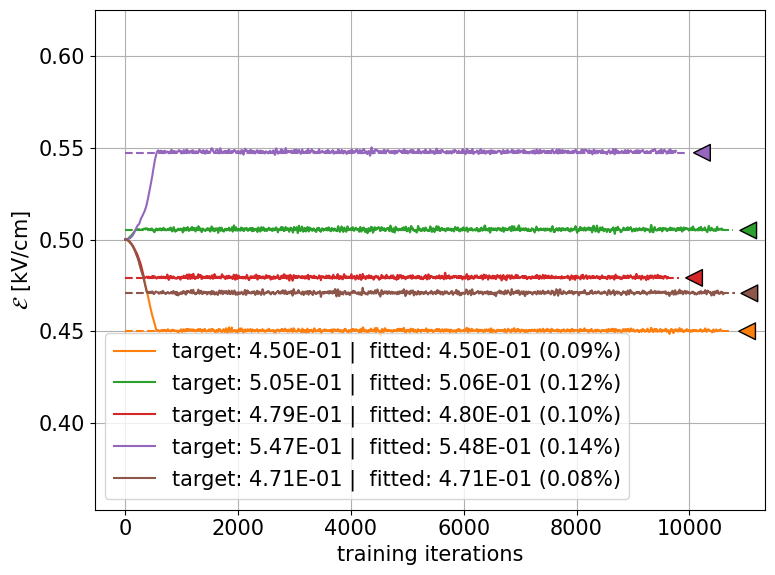

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

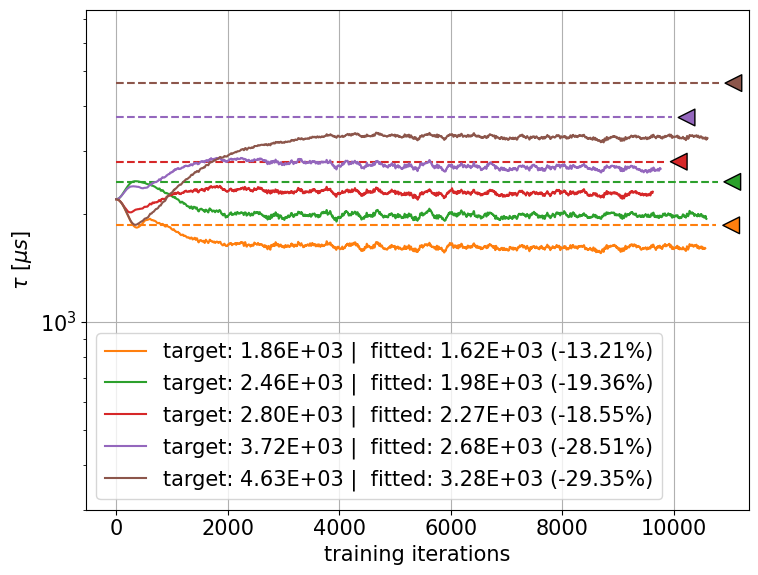

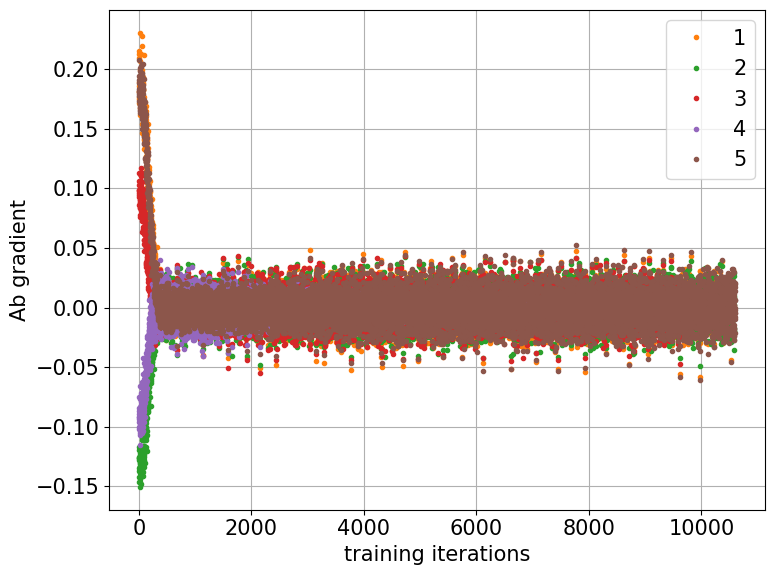

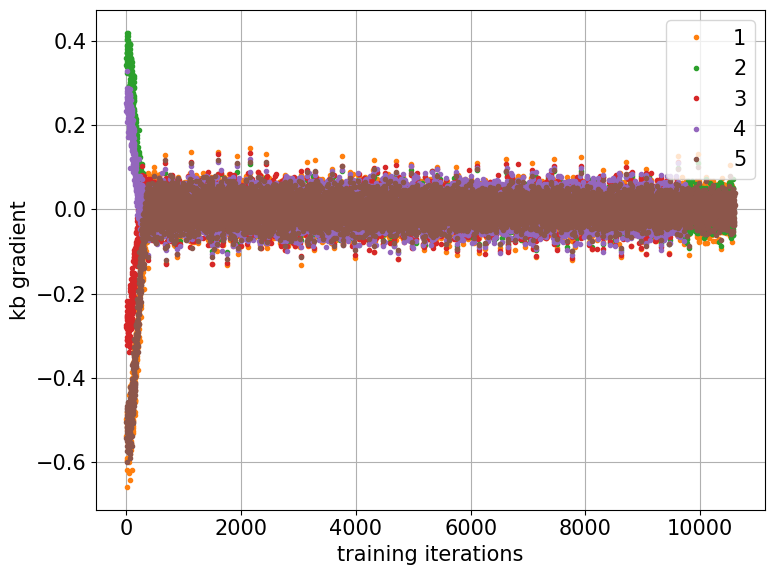

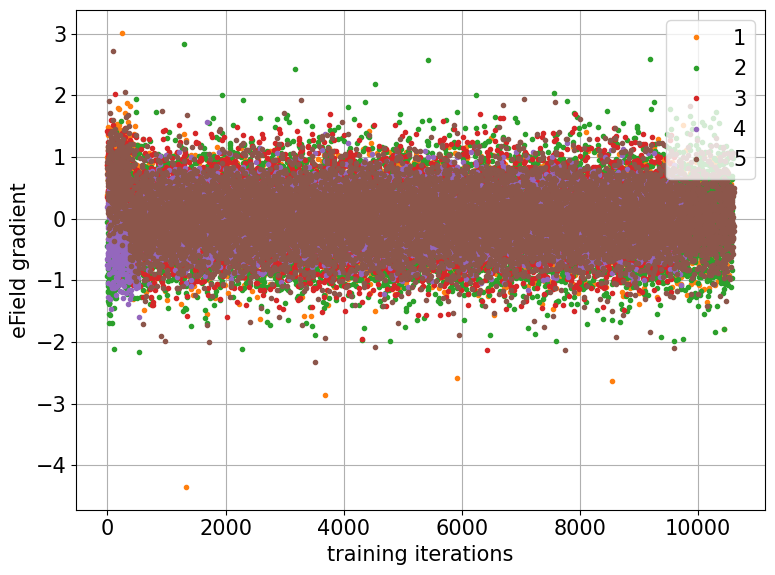

/lscratch/cyifan/tmp/ipykernel_3743180/2388119972.py:111: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc="upper right")


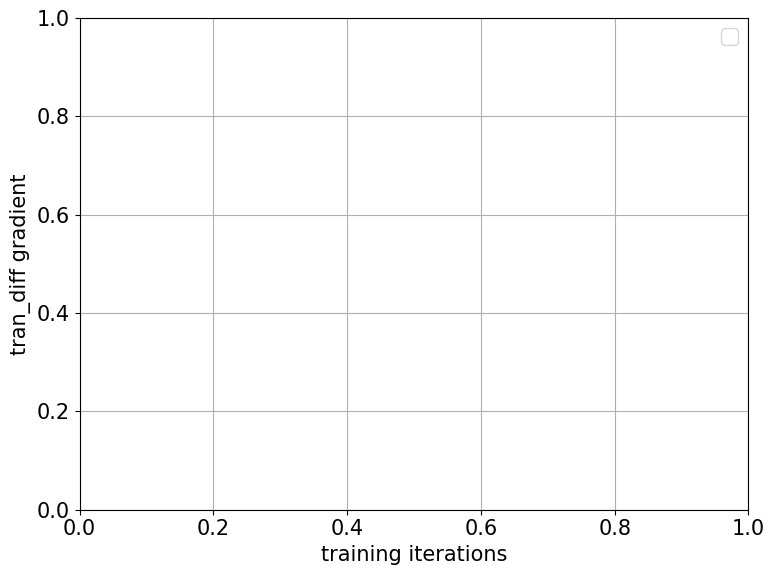

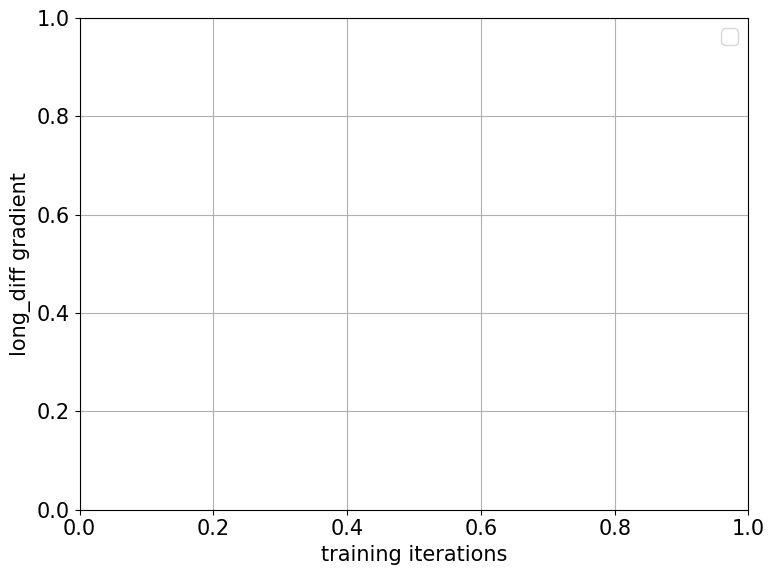

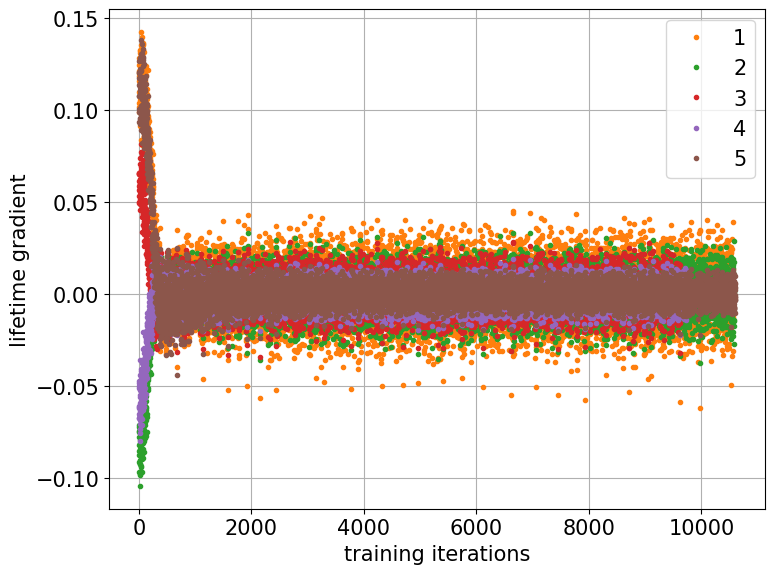

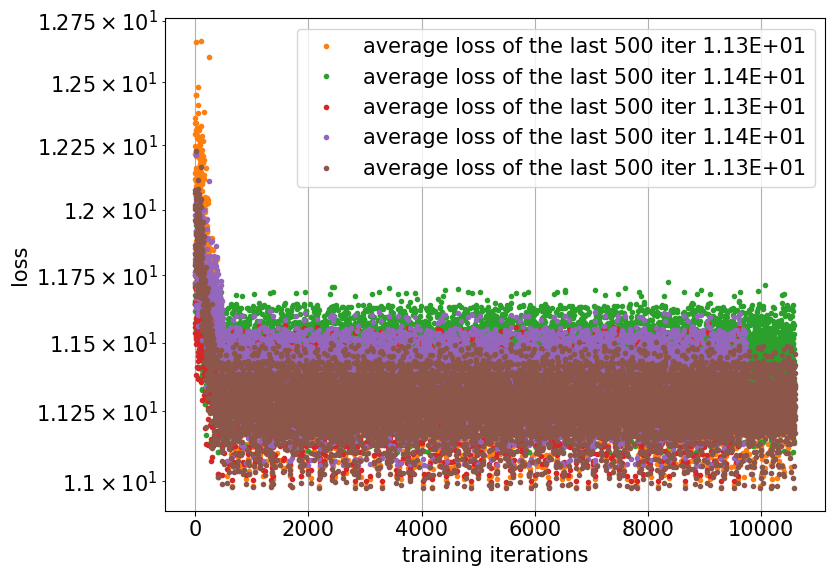

In [3]:
param_list = ["Ab", "kb", "eField", "tran_diff", "long_diff", "lifetime"]

labels = {'Ab' : '$A_B$',
          'kb' : '$k_B$ [kV$\cdot$g/cm$^3$/MeV]',
          'lifetime' : '$\\tau$ [$\mu s$]' ,
          'long_diff' : '$D_L$ [$cm^2/\mu s$]',
          'tran_diff' : '$D_T$ [$cm^2/\mu s$]',
          'vdrift' : 'vdrift [$cm/\mu s$]',
          'eField' : '$\mathcal{E}$ [kV/cm]',
          'shift_x' : 'shift x [cm]',
          'shift_y' : 'shift y [cm]',
          'shift_z' : 'shift z [cm]',
         }

root_dir="/sdf/group/neutrino/cyifan/diff_sim_playground/larndsim_loss_dQdx/"
label=f"A2-B5-C2-D10_4par_reco_pos_dE_density_no_diffusion_par_lr2_stopp_dx0.01_prob_mllhd_tQ_sQ5p0_at_per_track_ls0p2_tgtsimsd_different_nneigh4_lut_sigL200_gradclip1_bt200_nbt500_dtsd1_adam_dqdt_radial_sigmoid"
# label=f"A2-B5-C2-D2_reco_pos_dE_density_no_diffusion_par_lr2_stopp_dx0.01_prob_noise_tgtsim_seed_different_n_neigh4_lut_e_sampling_0.01cm_signalL200_gradclip1_warmup_exponential_decay_schedule_bt200_nbtach500_dtsd1_adam_llhd_sigmoid"

n_iter = -1

for i_par, param in enumerate(param_list):
    try:
        fig = plt.figure(figsize=(8, 6))
        tgt = []
        for seed in range(1,6):
            fname = f"fit_result/fit_noise/history_iter*_{label}_tgtsd{seed}.pkl"
            pkl_files_par_clip = glob(root_dir + fname)
            # print(fname)
            
            if len(pkl_files_par_clip) > 0:
                # pkl_file = pkl_files_par_clip[0]
                pkl_file = pkl_files_par_clip[-1]
                # print(pkl_file)

            if len(pkl_files_par_clip)!= 1:
                print(pkl_files_par_clip)
            # print(pkl_file)
            history = pickle.load(open(pkl_file, "rb"))
            # print(history.keys())
        
            # plt.plot(np.asarray(history["losses_iter"]),c=f'C{seed}')
            percent = (np.mean(history[param + "_iter"][n_iter-500:n_iter]) - history[param + "_target"][0]) / history[param + "_target"][0] * 100
            # par_label = f'target: {history[param + "_target"][0]:.3f} |  fitted: {np.mean(history[param + "_iter"][-500:]):.3f} ({percent:.3f}%)'
            par_label = f'target: {history[param + "_target"][0]:.2E} |  fitted: {np.mean(history[param + "_iter"][-1000:]):.2E} ({percent:.2f}%)'
            plt.plot(np.asarray(history[param + "_iter"][:n_iter]),c=f'C{seed}', label= par_label)
            plt.plot([0, len(history[param + "_iter"][:n_iter]) + 200], [history[param + "_target"], history[param + "_target"]], c=f'C{seed}', ls='dashed')
            
            plt.annotate(
                '',
                # f'target: {history[param + "_target"][0]:.3f} |  fitted: {np.mean(history[param + "_iter"][-500:]):.3f} ({percent:.3f}%)',  # The text to display, formatted to 2 decimal places
                xy=(len(history[param + "_iter"][:n_iter]) + 300, history[param + "_target"][0]),  # The (x, y) coordinates of the point to annotate
                xytext=(len(history[param + "_iter"][:n_iter]) + 600, history[param + "_target"][0]),  # The (x, y) coordinates for the text position
                arrowprops=dict(facecolor=f'C{seed}', shrink=0.05), # Optional: add an arrow pointing to the point
                horizontalalignment='left',
                verticalalignment='bottom'
            )
            tgt.append(history[param + "_target"][0])
    except:
        continue
        
    plt.xlabel("training iterations")
    plt.ylabel(labels[param])
    plt.legend(loc="lower left")
    # plt.ylabel("loss")
    #     plt.legend()
    plt.tight_layout()
    this_range = np.max(tgt) - np.min(tgt)
    if param == "lifetime":
        plt.yscale("log")
        plt.ylim(300, max(tgt)+this_range*1)
        # plt.ylim(300, max(tgt)+this_range*0.2)
    else:
        # plt.ylim(min(tgt)- this_range*2.5, max(tgt)+this_range*0.8)
        plt.ylim(min(tgt)- this_range*1, max(tgt)+this_range*0.8)
        # plt.ylim(min(tgt)- this_range*0.8, max(tgt)+this_range*0.3)
        if param == "Ab":
            plt.ylim(min(tgt)- this_range*0.8, max(tgt)+this_range*0.1)
        if param == "kb":
            plt.ylim(min(tgt)- this_range*0.8, max(tgt)+this_range*0.5)
    plt.grid()
    plt.savefig(root_dir + f"plots/{param}_{label}.png")
    plt.show()

for i_par, param in enumerate(param_list):
    fig = plt.figure(figsize=(8, 6))
    tgt = []
    for seed in range(1,6):
        try:
            fname = f"fit_result/fit_noise/history_iter*_{label}_tgtsd{seed}.pkl"
            pkl_files_par_clip = glob(root_dir + fname)
            # print(fname)
            
            if len(pkl_files_par_clip) > 0:
                # pkl_file = pkl_files_par_clip[0]
                pkl_file = pkl_files_par_clip[-1]
                # print(pkl_file)

            if len(pkl_files_par_clip)!= 1:
                print(pkl_files_par_clip)
            # print(pkl_file)
            history = pickle.load(open(pkl_file, "rb"))
            # print(history.keys())
        
            plt.plot(np.asarray(history[param + "_grad"]), ".",c=f'C{seed}', label=f"{seed}")
            # plt.plot([0, len(history[param + "_iter"]) + 200], [history[param + "_target"], history[param + "_target"]], c=f'C{seed}', ls='dashed')
        except:
            continue     
        
    plt.xlabel("training iterations")
    plt.ylabel(param + " gradient" )
    plt.legend(loc="upper right")
    # plt.ylabel("loss")
    #     plt.legend()
    plt.tight_layout()
    plt.grid()
    plt.savefig(root_dir + f"plots/grad_{param}_{label}.png")
    plt.show()

fig = plt.figure(figsize=(8, 6))
for seed in range(1,6):
    try:
        fname = f"fit_result/fit_noise/history_iter*_{label}_tgtsd{seed}.pkl"
        pkl_files_par_clip = glob(root_dir + fname)
        # print(fname)
        
        if len(pkl_files_par_clip) > 0:
            # pkl_file = pkl_files_par_clip[0]
            pkl_file = pkl_files_par_clip[-1]
            # print(pkl_file)

        if len(pkl_files_par_clip)!= 1:
            print(pkl_files_par_clip)
        # print(pkl_file)
        history = pickle.load(open(pkl_file, "rb"))
        # print(history.keys())
    
        plt.plot(np.asarray(history["losses_iter"]), ".",c=f'C{seed}', label=f"average loss of the last 500 iter {np.mean(history['losses_iter'][-1000:]):.2E}")
    except:
        print(f"Error occurred while processing seed {seed}")
    
plt.ylabel("loss")
plt.xlabel("training iterations")
plt.tight_layout()
plt.grid()
plt.yscale("log")
# this_range = np.max(history["losses_iter"]) - np.min(history["losses_iter"])
# plt.ylim(200, np.max(history["losses_iter"])+this_range*0.2)
plt.legend(loc="upper right")
plt.savefig(root_dir + f"plots/losses_{label}.png")
plt.show()
        

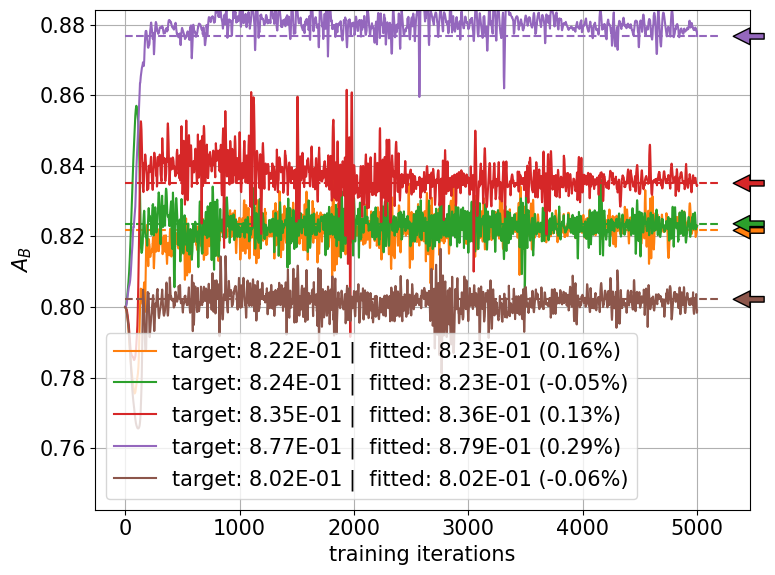

<Figure size 800x600 with 0 Axes>

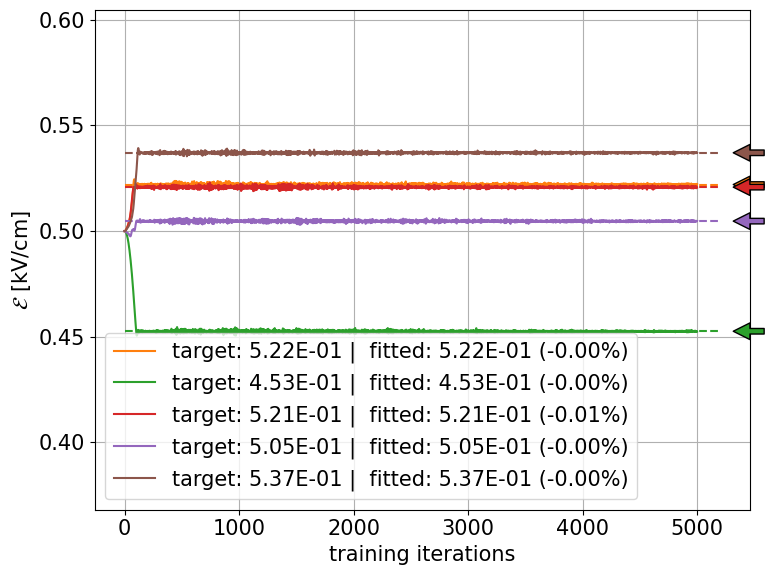

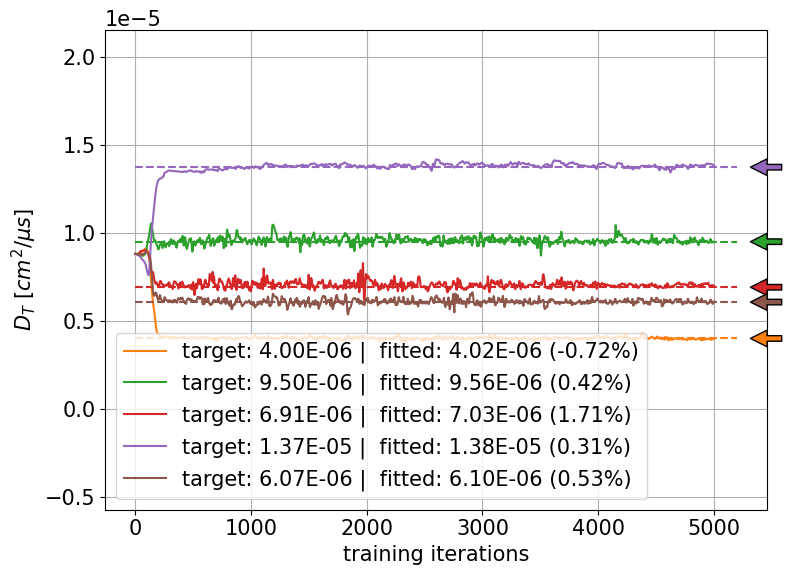

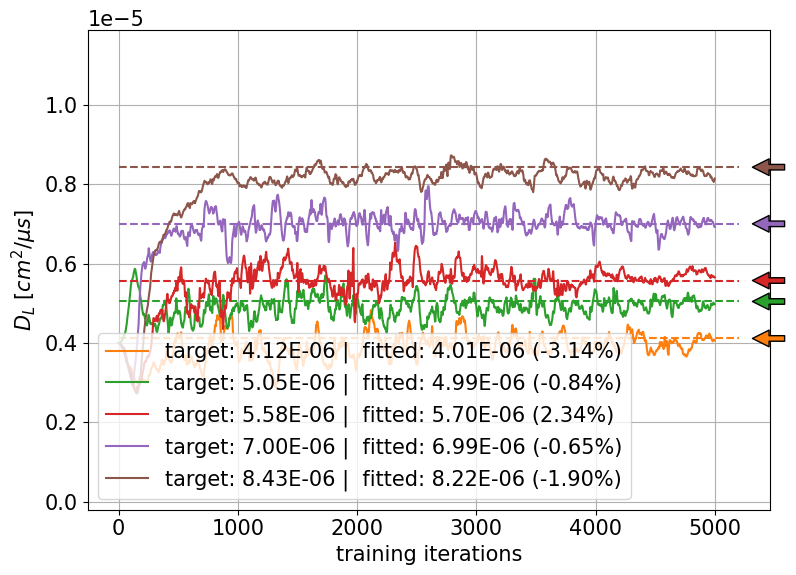

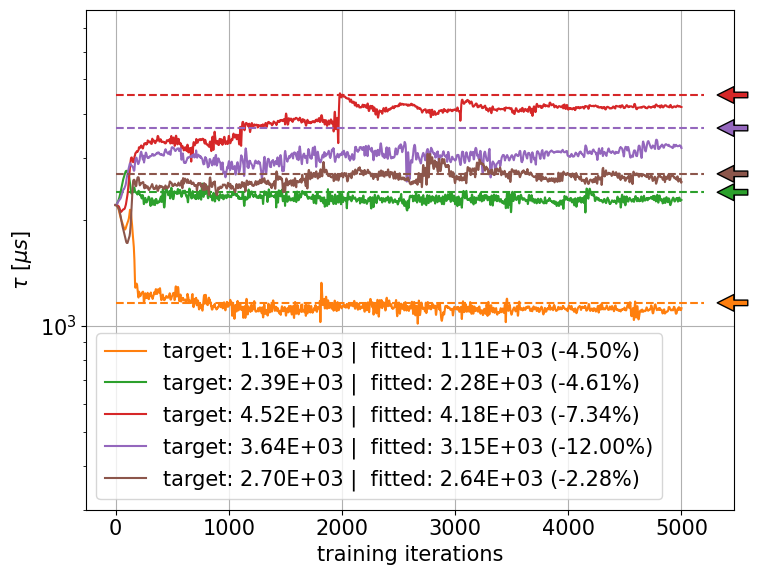

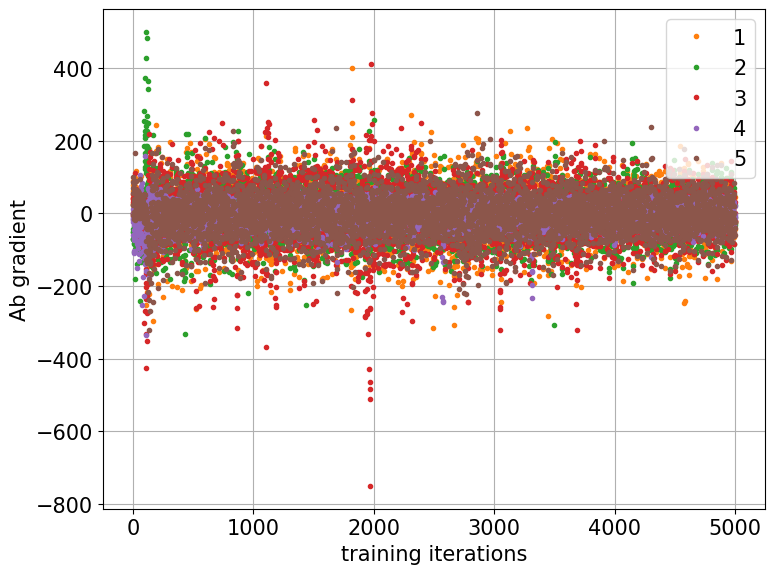

KeyError: 'kb_grad'

<Figure size 800x600 with 0 Axes>

In [ ]:
param_list = ["Ab", "kb", "eField", "tran_diff", "long_diff", "lifetime"]

labels = {'Ab' : '$A_B$',
          'kb' : '$k_B$ [kV$\cdot$g/cm$^3$/MeV]',
          'lifetime' : '$\\tau$ [$\mu s$]' ,
          'long_diff' : '$D_L$ [$cm^2/\mu s$]',
          'tran_diff' : '$D_T$ [$cm^2/\mu s$]',
          'vdrift' : 'vdrift [$cm/\mu s$]',
          'eField' : '$\mathcal{E}$ [kV/cm]',
          'shift_x' : 'shift x [cm]',
          'shift_y' : 'shift y [cm]',
          'shift_z' : 'shift z [cm]',
         }

root_dir="/sdf/group/neutrino/cyifan/diff_sim_playground/larndsim_dEdx_dist/"
# input_dir="/sdf/group/neutrino/pgranger/larnd-sim-jax/fit_result/fit_noise_dedx_28870155/" # real target
input_dir="/sdf/group/neutrino/pgranger/larnd-sim-jax/fit_result/fit_noise_dedx_27318914/" # target sampled from probabilistic distribution
label=f"true_throughmuons_6par_dedxfit_priw0.5_dlr1e-2_dsi0_noise_tgtsim_n_neigh4_mode_lut_e_sampling_0.01cm_seed_stgy_random_grad_clip100_warmup_exponential_decay_schedule_bt200"

for i_par, param in enumerate(param_list):
    try:
        fig = plt.figure(figsize=(8, 6))
        tgt = []
        for seed in range(1,6):
            fname = f"history_iter*_{label}_tgtsd{seed}_dtsd1_adam_llhd*.pkl"
            pkl_files_par_clip = glob(input_dir + "/" + fname)
            # print(fname)
            
            if len(pkl_files_par_clip) > 0:
                # pkl_file = pkl_files_par_clip[0]
                pkl_file = pkl_files_par_clip[-1]
                # print(pkl_file)

            if len(pkl_files_par_clip)!= 1:
                print(pkl_files_par_clip)
            # print(pkl_file)
            history = pickle.load(open(pkl_file, "rb"))
            # print(history.keys())
        
            # plt.plot(np.asarray(history["losses_iter"]),c=f'C{seed}')
            percent = (np.mean(history[param + "_iter"][-500:]) - history[param + "_target"][0]) / history[param + "_target"][0] * 100
            # par_label = f'target: {history[param + "_target"][0]:.3f} |  fitted: {np.mean(history[param + "_iter"][-500:]):.3f} ({percent:.3f}%)'
            par_label = f'target: {history[param + "_target"][0]:.2E} |  fitted: {np.mean(history[param + "_iter"][-1000:]):.2E} ({percent:.2f}%)'
            plt.plot(np.asarray(history[param + "_iter"]),c=f'C{seed}', label= par_label)
            plt.plot([0, len(history[param + "_iter"]) + 200], [history[param + "_target"], history[param + "_target"]], c=f'C{seed}', ls='dashed')
            
            plt.annotate(
                '',
                # f'target: {history[param + "_target"][0]:.3f} |  fitted: {np.mean(history[param + "_iter"][-500:]):.3f} ({percent:.3f}%)',  # The text to display, formatted to 2 decimal places
                xy=(len(history[param + "_iter"]) + 300, history[param + "_target"][0]),  # The (x, y) coordinates of the point to annotate
                xytext=(len(history[param + "_iter"]) + 600, history[param + "_target"][0]),  # The (x, y) coordinates for the text position
                arrowprops=dict(facecolor=f'C{seed}', shrink=0.05), # Optional: add an arrow pointing to the point
                horizontalalignment='left',
                verticalalignment='bottom'
            )
            tgt.append(history[param + "_target"][0])
    except:
        continue
        
    plt.xlabel("training iterations")
    plt.ylabel(labels[param])
    plt.legend(loc="lower left")
    # plt.ylabel("loss")
    #     plt.legend()
    plt.tight_layout()
    this_range = np.max(tgt) - np.min(tgt)
    if param == "lifetime":
        plt.yscale("log")
        plt.ylim(300, max(tgt)+this_range*1)
        # plt.ylim(300, max(tgt)+this_range*0.2)
    else:
        # plt.ylim(min(tgt)- this_range*2.5, max(tgt)+this_range*0.8)
        plt.ylim(min(tgt)- this_range*1, max(tgt)+this_range*0.8)
        # plt.ylim(min(tgt)- this_range*0.8, max(tgt)+this_range*0.3)
    plt.grid()
    plt.savefig(root_dir + f"plots/{param}_{label}.png")
    plt.show()

for i_par, param in enumerate(param_list):
    fig = plt.figure(figsize=(8, 6))
    tgt = []
    for seed in range(1,6):
        fname = f"history_iter*_{label}_tgtsd{seed}*.pkl"
        pkl_files_par_clip = glob(input_dir + fname)
        # print(fname)
        
        if len(pkl_files_par_clip) > 0:
            # pkl_file = pkl_files_par_clip[0]
            pkl_file = pkl_files_par_clip[-1]
            # print(pkl_file)

        if len(pkl_files_par_clip)!= 1:
            print(pkl_files_par_clip)
        # print(pkl_file)
        history = pickle.load(open(pkl_file, "rb"))
        # print(history.keys())
    
        plt.plot(np.asarray(history[param + "_grad"]), ".",c=f'C{seed}', label=f"{seed}")
        # plt.plot([0, len(history[param + "_iter"]) + 200], [history[param + "_target"], history[param + "_target"]], c=f'C{seed}', ls='dashed')
        
        
    plt.xlabel("training iterations")
    plt.ylabel(param + " gradient" )
    plt.legend(loc="upper right")
    # plt.ylabel("loss")
    #     plt.legend()
    plt.tight_layout()
    plt.grid()
    plt.savefig(root_dir + f"plots/grad_{param}_{label}.png")
    plt.show()

fig = plt.figure(figsize=(8, 6))
for seed in range(1,6):
    fname = f"history_iter*_{label}_tgtsd{seed}*.pkl"
    pkl_files_par_clip = glob(root_dir + fname)

    if len(pkl_files_par_clip) > 0:
        pkl_file = pkl_files_par_clip[0]

    # print(pkl_file)
    history = pickle.load(open(pkl_file, "rb"))

    plt.plot(np.asarray(history["losses_iter"]), ".",c=f'C{seed}', label=f"average loss of the last 500 iter {np.mean(history['losses_iter'][-1000:]):.2E}")
    
plt.ylabel("loss")
plt.xlabel("training iterations")
plt.tight_layout()
plt.grid()
plt.yscale("log")
# this_range = np.max(history["losses_iter"]) - np.min(history["losses_iter"])
# plt.ylim(200, np.max(history["losses_iter"])+this_range*0.2)
plt.legend(loc="upper right")
plt.savefig(root_dir + f"plots/losses_{label}.png")
plt.show()
        

In [10]:
history['config']

Namespace(param_list=['optimize/scripts/param_list_main.yaml'], input_file_sim='/sdf/data/neutrino/cyifan/diffsim_input/true_proton_edep_2cm_range_0.1-cm_dEdx.h5', input_file_tgt='/sdf/data/neutrino/cyifan/diffsim_input/true_proton_edep_2cm_range_0.1-cm.h5', detector_props='src/larndsim/detector_properties/module0.yaml', pixel_layouts='src/larndsim/pixel_layouts/multi_tile_layout-2.4.16_v4.yaml', lr=1, batch_sz=1, epochs=100, seed=5, data_seed=1, shuffle_seed=42, vary_init=False, data_sz=-1, no_noise=False, no_noise_target=False, no_noise_guess=False, save_freq=10, random_nevents=False, track_len_sel=2.0, max_abs_costheta_sel=0.966, min_abs_segz_sel=15.0, track_z_bound=28.0, out_label='stopp_reco_dE_dxvaried_lr0.01_prob_noise_tgtsim_seed_different_n_neigh4_lut_e_sampling_0.01cm_signalL200_gradclip1_warmup_exponential_decay_schedule_bt200_nbtach500_dtsd1_adam_mse_adc_sigmoid_tgtsd5', test_name='fit_noise', fixed_range=None, max_clip_norm_val=1.0, clip_from_range=True, optimizer_fn='Adam

Loaded target dE/dx samples: 3030787
Loading: /sdf/group/neutrino/pgranger/larnd-sim-jax/fit_result/fit_noise_dedx_27318914/history_iter5000_true_throughmuons_6par_dedxfit_priw0.5_dlr1e-2_dsi0_noise_tgtsim_n_neigh4_mode_lut_e_sampling_0.01cm_seed_stgy_random_grad_clip100_warmup_exponential_decay_schedule_bt200_tgtsd1_dtsd1_adam_llhd.pkl
Keys in history: ['Ab', 'Ab_target', 'Ab_init', 'eField', 'eField_target', 'eField_init', 'tran_diff', 'tran_diff_target', 'tran_diff_init', 'long_diff', 'long_diff_target', 'long_diff_init', 'lifetime', 'lifetime_target', 'lifetime_init', 'shift_x', 'shift_x_target', 'shift_x_init', 'shift_y', 'shift_y_target', 'shift_y_init', 'shift_z', 'shift_z_target', 'shift_z_init', 'size_history', 'memory', 'config', 'optimizer_fn_name', 'Ab_grad', 'Ab_iter', 'eField_grad', 'eField_iter', 'tran_diff_grad', 'tran_diff_iter', 'long_diff_grad', 'long_diff_iter', 'lifetime_grad', 'lifetime_iter', 'shift_x_grad', 'shift_x_iter', 'shift_y_grad', 'shift_y_iter', 'shift_

/lscratch/cyifan/tmp/ipykernel_2359579/2258992530.py:109: UserWarning:

Data has no positive values, and therefore cannot be log-scaled.



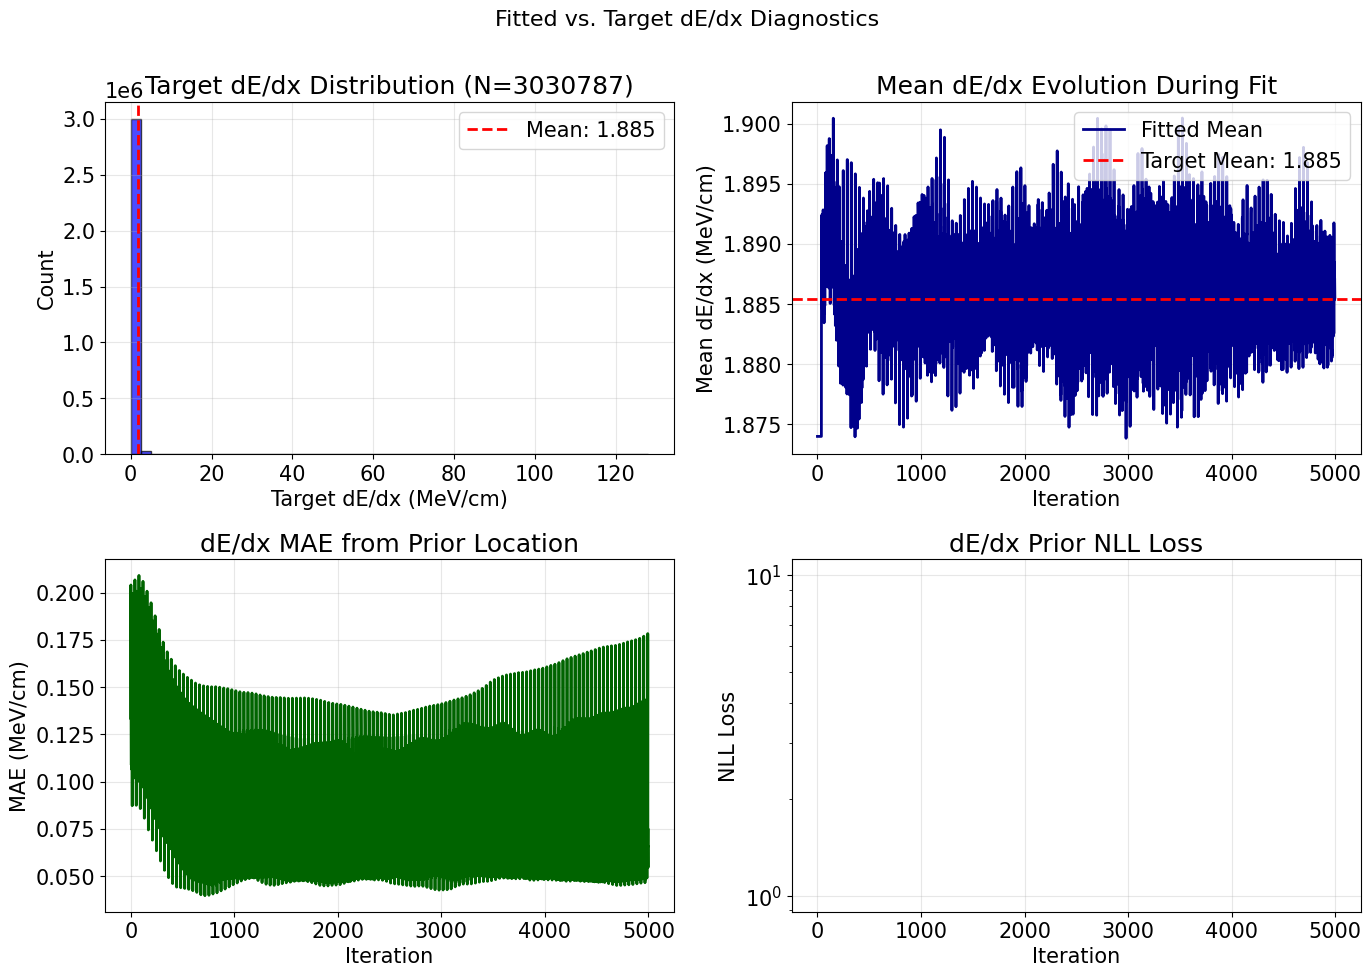

Mean target dE/dx: 1.8854 MeV/cm
Final fitted mean dE/dx: 1.8856 MeV/cm


In [34]:
# Plot fitted vs. target dE/dx (matplotlib)
import h5py

input_dir = "/sdf/group/neutrino/pgranger/larnd-sim-jax/fit_result/fit_noise_dedx_27318914/"
label = f"true_throughmuons_6par_dedxfit_priw0.5_dlr1e-2_dsi0_noise_tgtsim_n_neigh4_mode_lut_e_sampling_0.01cm_seed_stgy_random_grad_clip100_warmup_exponential_decay_schedule_bt200"
target_h5 = "/sdf/data/neutrino/cyifan/diffsim_input/true_through_muon_edep_10cm_vol1cm.h5"

# Load target dE/dx from segment dataset
target_dedx = []
try:
    with h5py.File(target_h5, 'r') as f:
        if 'segments' in f:
            seg_data = f['segments']
            if 'dEdx' in seg_data.dtype.names:
                target_dedx = np.array(seg_data['dEdx'])
        
        # Fallback: try to infer from common keys
        if len(target_dedx) == 0:
            print(f"Available keys: {list(f.keys())}")
            for key in f.keys():
                print(f"  {key}: {type(f[key])}")
                if isinstance(f[key], h5py.Group):
                    print(f"    Subkeys: {list(f[key].keys())}")
except Exception as e:
    print(f"Error loading target dE/dx: {e}")

print(f"Loaded target dE/dx samples: {len(target_dedx)}")

# Load fitted dE/dx history
mean_dedx_fitted = []
dedx_mae = []
dedx_prior_loss = []

try:
    pkl_file = glob(input_dir + f"history_iter*{label}*.pkl")
    if len(pkl_file) > 0:
        pkl_file = pkl_file[-1]  # Latest checkpoint
        print(f"Loading: {pkl_file}")
        history = pickle.load(open(pkl_file, "rb"))
        
        if 'mean_dedx_iter' in history:
            mean_dedx_fitted = history['mean_dedx_iter']
        if 'dedx_mae_iter' in history:
            dedx_mae = history['dedx_mae_iter']
        if 'dedx_prior_iter' in history:
            dedx_prior_loss = history['dedx_prior_iter']
        
        print(f"Keys in history: {list(history.keys())}")
    else:
        print(f"No pickle files found in {input_dir} with label {label}")
        pkl_files = glob(input_dir + "history_iter*.pkl")
        print(f"Available files: {pkl_files[:5]}")
except Exception as e:
    print(f"Error loading pickle: {e}")

# Create matplotlib figure
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Fitted vs. Target dE/dx Diagnostics', fontsize=16)

# Plot 1: Target dE/dx distribution
ax = axes[0, 0]
if len(target_dedx) > 0:
    ax.hist(target_dedx, bins=50, alpha=0.7, color='blue', edgecolor='black')
    ax.set_xlabel('Target dE/dx (MeV/cm)')
    ax.set_ylabel('Count')
    ax.set_title(f'Target dE/dx Distribution (N={len(target_dedx)})')
    ax.grid(alpha=0.3)
    ax.axvline(np.mean(target_dedx), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(target_dedx):.3f}')
    ax.legend()
else:
    ax.text(0.5, 0.5, 'No target dE/dx data loaded', ha='center', va='center')
    ax.set_title('Target dE/dx Distribution')

# Plot 2: Mean dE/dx evolution
ax = axes[0, 1]
if len(mean_dedx_fitted) > 0:
    ax.plot(mean_dedx_fitted, linewidth=2, color='darkblue', label='Fitted Mean')
    if len(target_dedx) > 0:
        ax.axhline(np.mean(target_dedx), color='red', linestyle='--', linewidth=2, label=f'Target Mean: {np.mean(target_dedx):.3f}')
    ax.set_xlabel('Iteration')
    ax.set_ylabel('Mean dE/dx (MeV/cm)')
    ax.set_title('Mean dE/dx Evolution During Fit')
    ax.grid(alpha=0.3)
    ax.legend()
else:
    ax.text(0.5, 0.5, 'No fitted mean dE/dx history', ha='center', va='center')
    ax.set_title('Mean dE/dx Evolution')

# Plot 3: dE/dx MAE from prior
ax = axes[1, 0]
if len(dedx_mae) > 0:
    ax.plot(dedx_mae, linewidth=2, color='darkgreen')
    ax.set_xlabel('Iteration')
    ax.set_ylabel('MAE (MeV/cm)')
    ax.set_title('dE/dx MAE from Prior Location')
    ax.grid(alpha=0.3)
else:
    ax.text(0.5, 0.5, 'No MAE history', ha='center', va='center')
    ax.set_title('dE/dx MAE')

# Plot 4: Prior loss (NLL)
ax = axes[1, 1]
if len(dedx_prior_loss) > 0:
    ax.plot(dedx_prior_loss, linewidth=2, color='darkorange')
    ax.set_xlabel('Iteration')
    ax.set_ylabel('NLL Loss')
    ax.set_title('dE/dx Prior NLL Loss')
    ax.grid(alpha=0.3)
    ax.set_yscale('log')
else:
    ax.text(0.5, 0.5, 'No prior loss history', ha='center', va='center')
    ax.set_title('dE/dx Prior Loss')

plt.tight_layout()
plt.show()

print(f"Mean target dE/dx: {np.mean(target_dedx):.4f} MeV/cm" if len(target_dedx) > 0 else "No target data")
print(f"Final fitted mean dE/dx: {mean_dedx_fitted[-1]:.4f} MeV/cm" if len(mean_dedx_fitted) > 0 else "No fitted data")


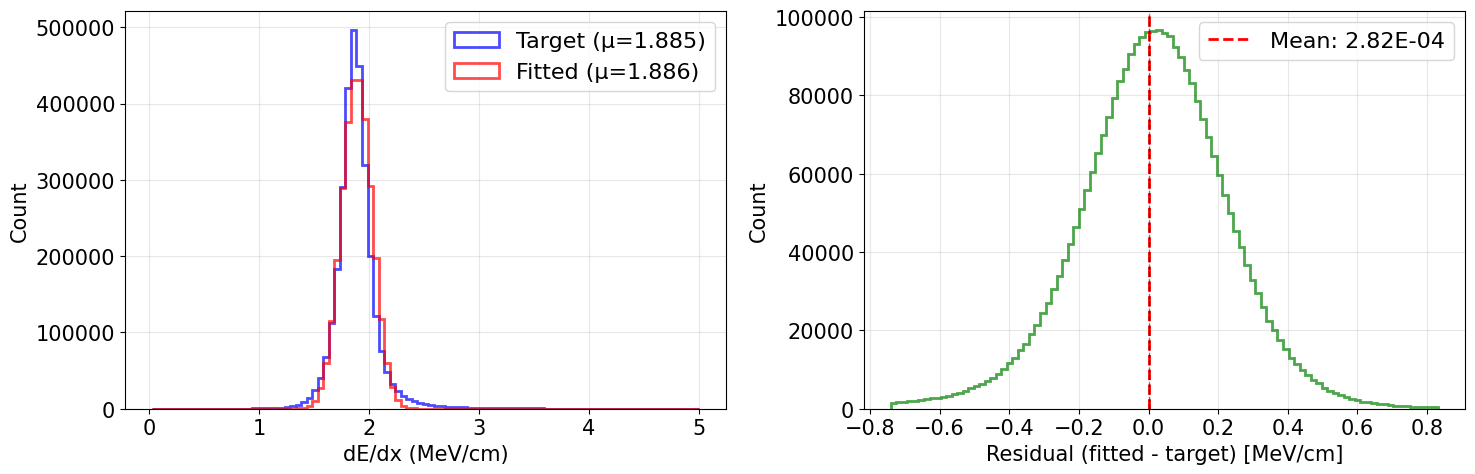


=== Per-Segment dE/dx Statistics ===
Target:  mean=1.8854, std=0.2760, n=3030787
Fitted:  mean=1.8857, std=0.1379
Residual: mean=0.0003, std=0.3085
MAE: 0.1783
Median |residual|: 0.1358
Residual range: [-126.0447, 2.0315]


In [43]:
# Create 2x1 comparison figure if we have both datasets
if len(target_dedx) > 0 and fitted_dedx is not None:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    # fig.suptitle('Per-Segment dE/dx: Fitted vs Target Comparison', fontsize=14)
    
    # Plot 1: Overlaid histograms comparison (step histograms)
    ax = axes[0]
    # bins = np.linspace(max(0, min(np.min(target_dedx), np.min(fitted_dedx)) - 0.2), 
    #                     min(5, max(np.max(target_dedx), np.max(fitted_dedx)) + 0.2), 100)
    bins = np.linspace(max(0, min(np.min(target_dedx), np.min(fitted_dedx))), 
                        min(5, max(np.max(target_dedx), np.max(fitted_dedx))), 100)
    ax.hist(target_dedx, bins=bins, alpha=0.7, color='blue', label=f'Target (μ={np.mean(target_dedx):.3f})', 
            histtype='step', linewidth=2)
    ax.hist(fitted_dedx, bins=bins, alpha=0.7, color='red', label=f'Fitted (μ={np.mean(fitted_dedx):.3f})', 
            histtype='step', linewidth=2)
    ax.set_xlabel('dE/dx (MeV/cm)')
    ax.set_ylabel('Count')
    # ax.set_title('1D Histogram: Fitted vs Target dE/dx')
    ax.legend(fontsize=16)
    ax.grid(alpha=0.3)
    
    # Plot 2: Residual histogram (step histogram)
    ax = axes[1]
    residuals = fitted_dedx - target_dedx
    residual_bins = np.linspace(np.percentile(residuals, 1), np.percentile(residuals, 99.9), 100)
    ax.hist(residuals, bins=residual_bins, alpha=0.7, color='green', histtype='step', linewidth=2)
    ax.set_xlabel('Residual (fitted - target) [MeV/cm]')
    ax.set_ylabel('Count')
    # ax.set_title(f'Per-Segment Residuals (μ={np.mean(residuals):.4f}, σ={np.std(residuals):.4f})')
    ax.axvline(np.mean(residuals), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(residuals):.2E}')
    ax.axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.legend(fontsize=16)
    ax.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print(f"\n=== Per-Segment dE/dx Statistics ===")
    print(f"Target:  mean={np.mean(target_dedx):.4f}, std={np.std(target_dedx):.4f}, n={len(target_dedx)}")
    print(f"Fitted:  mean={np.mean(fitted_dedx):.4f}, std={np.std(fitted_dedx):.4f}")
    print(f"Residual: mean={np.mean(residuals):.4f}, std={np.std(residuals):.4f}")
    print(f"MAE: {np.mean(np.abs(residuals)):.4f}")
    print(f"Median |residual|: {np.median(np.abs(residuals)):.4f}")
    print(f"Residual range: [{np.min(residuals):.4f}, {np.max(residuals):.4f}]")
    
else:
    print("Cannot create comparison: need both target and fitted dE/dx per-segment data")
    print(f"Target loaded: {len(target_dedx) > 0}, Fitted available: {fitted_dedx is not None}")